# CodSoft Week 3 – E-Commerce Business Analytics

## Dataset
Olist Brazilian E-Commerce Public Dataset

## Tools
Python, Pandas, NumPy, Matplotlib, Google Colab, Power BI

## Objective
Analyze e-commerce sales, customer behavior, product performance,
category performance, regional performance, and business trends.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/CodSoft_Week3_Ecommerce_Analytics"

RAW_PATH = os.path.join(
    PROJECT_PATH,
    "Raw_Data"
)

print("Project path:")
print(PROJECT_PATH)

print("\nRaw data path:")
print(RAW_PATH)

Project path:
/content/drive/MyDrive/CodSoft_Week3_Ecommerce_Analytics

Raw data path:
/content/drive/MyDrive/CodSoft_Week3_Ecommerce_Analytics/Raw_Data


In [ ]:
print("Raw_Data folder exists:", os.path.exists(RAW_PATH))

Raw_Data folder exists: True


In [ ]:
os.listdir(RAW_PATH)

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

In [ ]:
def load_raw_csv(filename):
    file_path = os.path.join(RAW_PATH, filename)

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"File not found: {file_path}"
        )

    return pd.read_csv(file_path)

In [ ]:
CLEAN_PATH = os.path.join(
    PROJECT_PATH,
    "02_Cleaned_Data"
)

os.makedirs(
    CLEAN_PATH,
    exist_ok=True
)

print("Cleaned Data folder ready:")
print(CLEAN_PATH)

Cleaned Data folder ready:
/content/drive/MyDrive/CodSoft_Week3_Ecommerce_Analytics/02_Cleaned_Data


In [ ]:
csv_files = [
    'olist_customers_dataset.csv',
    'olist_geolocation_dataset.csv',
    'olist_order_items_dataset.csv',
    'olist_order_payments_dataset.csv',
    'olist_order_reviews_dataset.csv',
    'olist_orders_dataset.csv',
    'olist_products_dataset.csv',
    'olist_sellers_dataset.csv',
    'product_category_name_translation.csv'
]

datasets = {}
for file in csv_files:
    name = file.replace('.csv', '')
    datasets[name] = load_raw_csv(file)

for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 60)
    print(list(df.columns))


olist_customers_dataset
------------------------------------------------------------
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

olist_geolocation_dataset
------------------------------------------------------------
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

olist_order_items_dataset
------------------------------------------------------------
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

olist_order_payments_dataset
------------------------------------------------------------
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

olist_order_reviews_dataset
------------------------------------------------------------
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

oli

In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 60)
    print(df.dtypes)


olist_customers_dataset
------------------------------------------------------------
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

olist_geolocation_dataset
------------------------------------------------------------
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

olist_order_items_dataset
------------------------------------------------------------
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

olist_order_payments_dataset
------------------------------------------------------------
order_id          

In [ ]:
#missing values check
for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 60)
    print(df.isnull().sum())


olist_customers_dataset
------------------------------------------------------------
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

olist_geolocation_dataset
------------------------------------------------------------
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

olist_order_items_dataset
------------------------------------------------------------
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

olist_order_payments_dataset
------------------------------------------------------------
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value 

In [ ]:
#duplicate rows check
for name, df in datasets.items():
    print(f"{name:<22} duplicates: {df.duplicated().sum():,}")

olist_customers_dataset duplicates: 0
olist_geolocation_dataset duplicates: 261,831
olist_order_items_dataset duplicates: 0
olist_order_payments_dataset duplicates: 0
olist_order_reviews_dataset duplicates: 0
olist_orders_dataset   duplicates: 0
olist_products_dataset duplicates: 0
olist_sellers_dataset  duplicates: 0
product_category_name_translation duplicates: 0


In [ ]:
for name, df in datasets.items():
    print(
        f"{name:<22} "
        f"Rows: {len(df):,} | "
        f"Columns: {len(df.columns)}"
    )

olist_customers_dataset Rows: 99,441 | Columns: 5
olist_geolocation_dataset Rows: 1,000,163 | Columns: 5
olist_order_items_dataset Rows: 112,650 | Columns: 7
olist_order_payments_dataset Rows: 103,886 | Columns: 5
olist_order_reviews_dataset Rows: 99,224 | Columns: 7
olist_orders_dataset   Rows: 99,441 | Columns: 8
olist_products_dataset Rows: 32,951 | Columns: 9
olist_sellers_dataset  Rows: 3,095 | Columns: 4
product_category_name_translation Rows: 71 | Columns: 2


In [ ]:
orders = datasets['olist_orders_dataset']
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
#inspect order items
order_items = datasets['olist_order_items_dataset']
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
#inspect customers
customers = datasets['olist_customers_dataset']
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
#inspect products
products = datasets['olist_products_dataset']
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
#inspect payments
payments = datasets['olist_order_payments_dataset']
payments.head()


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
#inspect reviews
reviews = datasets['olist_order_reviews_dataset']
reviews.head()
#


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
#inspect sellers
sellers = datasets['olist_sellers_dataset']
sellers.head()


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:
#inspect category translation
category_translation = datasets['product_category_name_translation']
category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [ ]:
#inspect geolocation
geolocation = datasets['olist_geolocation_dataset']
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


Checking the data quality

In [ ]:
print(orders[
    [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].head())

  order_purchase_timestamp    order_approved_at order_delivered_carrier_date  \
0      2017-10-02 10:56:33  2017-10-02 11:07:15          2017-10-04 19:55:00   
1      2018-07-24 20:41:37  2018-07-26 03:24:27          2018-07-26 14:31:00   
2      2018-08-08 08:38:49  2018-08-08 08:55:23          2018-08-08 13:50:00   
3      2017-11-18 19:28:06  2017-11-18 19:45:59          2017-11-22 13:39:59   
4      2018-02-13 21:18:39  2018-02-13 22:20:29          2018-02-14 19:46:34   

  order_delivered_customer_date order_estimated_delivery_date  
0           2017-10-10 21:25:13           2017-10-18 00:00:00  
1           2018-08-07 15:27:45           2018-08-13 00:00:00  
2           2018-08-17 18:06:29           2018-09-04 00:00:00  
3           2017-12-02 00:28:42           2017-12-15 00:00:00  
4           2018-02-16 18:17:02           2018-02-26 00:00:00  


In [ ]:
print(order_items[
    [
        "order_item_id",
        "price",
        "freight_value"
    ]
].describe())

       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000


In [ ]:
print(order_items[
    [
        "order_item_id",
        "price",
        "freight_value"
    ]
].describe())

       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000


In [ ]:
print(payments[
    [
        "payment_value",
        "payment_installments"
    ]
].describe())

       payment_value  payment_installments
count  103886.000000         103886.000000
mean      154.100380              2.853349
std       217.494064              2.687051
min         0.000000              0.000000
25%        56.790000              1.000000
50%       100.000000              1.000000
75%       171.837500              4.000000
max     13664.080000             24.000000


In [ ]:
print(payments[
    [
        "payment_value",
        "payment_installments"
    ]
].describe())

       payment_value  payment_installments
count  103886.000000         103886.000000
mean      154.100380              2.853349
std       217.494064              2.687051
min         0.000000              0.000000
25%        56.790000              1.000000
50%       100.000000              1.000000
75%       171.837500              4.000000
max     13664.080000             24.000000


In [ ]:
print(
    "Negative item prices:",
    (order_items["price"] < 0).sum()
)

print(
    "Negative freight values:",
    (order_items["freight_value"] < 0).sum()
)

Negative item prices: 0
Negative freight values: 0


In [ ]:
dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for column in dimension_columns:
    print(
        column,
        "negative values:",
        (products[column] < 0).sum()
    )

product_weight_g negative values: 0
product_length_cm negative values: 0
product_height_cm negative values: 0
product_width_cm negative values: 0


In [ ]:
print("Orders duplicate order_id:",
      orders["order_id"].duplicated().sum())

print("Customers duplicate customer_id:",
      customers["customer_id"].duplicated().sum())

print("Products duplicate product_id:",
      products["product_id"].duplicated().sum())

print("Sellers duplicate seller_id:",
      sellers["seller_id"].duplicated().sum())

Orders duplicate order_id: 0
Customers duplicate customer_id: 0
Products duplicate product_id: 0
Sellers duplicate seller_id: 0


In [ ]:
print("Orders duplicate order_id:",
      orders["order_id"].duplicated().sum())

print("Customers duplicate customer_id:",
      customers["customer_id"].duplicated().sum())

print("Products duplicate product_id:",
      products["product_id"].duplicated().sum())

print("Sellers duplicate seller_id:",
      sellers["seller_id"].duplicated().sum())

Orders duplicate order_id: 0
Customers duplicate customer_id: 0
Products duplicate product_id: 0
Sellers duplicate seller_id: 0


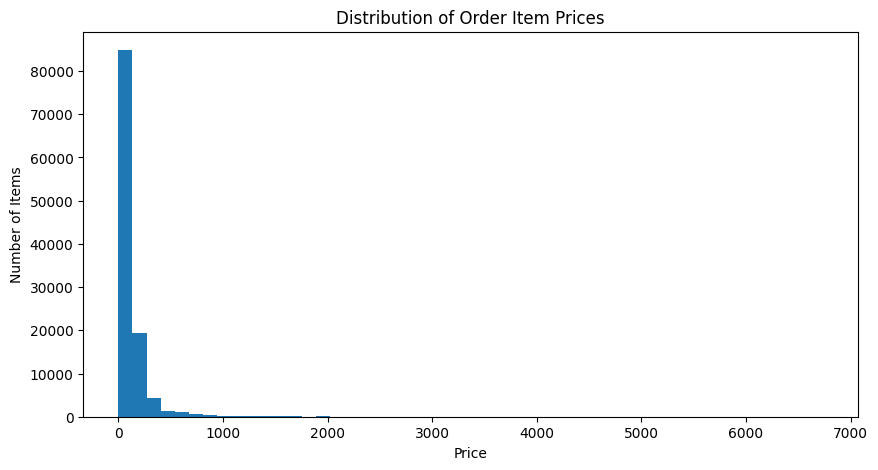

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(order_items["price"], bins=50)

plt.title("Distribution of Order Item Prices")
plt.xlabel("Price")
plt.ylabel("Number of Items")

plt.show()

In [ ]:
#order purchase dates
print(
    "Earliest purchase:",
    orders["order_purchase_timestamp"].min()
)

print(
    "Latest purchase:",
    orders["order_purchase_timestamp"].max()
)

Earliest purchase: 2016-09-04 21:15:19
Latest purchase: 2018-10-17 17:30:18


In [ ]:
#cleaning summary
cleaning_summary = []

for name, df in datasets.items():
    cleaning_summary.append({
        "Dataset": name,
        "Rows Before Cleaning": len(df),
        "Columns": len(df.columns),
        "Duplicate Rows": df.duplicated().sum(),
        "Missing Cells": df.isnull().sum().sum()
    })

cleaning_summary_df = pd.DataFrame(cleaning_summary)

cleaning_summary_df

,Dataset,Rows Before Cleaning,Columns,Duplicate Rows,Missing Cells
0,olist_customers_dataset,99441,5,0,0
1,olist_geolocation_dataset,1000163,5,261831,0
2,olist_order_items_dataset,112650,7,0,0
3,olist_order_payments_dataset,103886,5,0,0
4,olist_order_reviews_dataset,99224,7,0,145903
5,olist_orders_dataset,99441,8,0,4908
6,olist_products_dataset,32951,9,0,2448
7,olist_sellers_dataset,3095,4,0,0
8,product_category_name_translation,71,2,0,0


In [ ]:
orders_clean = orders.copy()
order_items_clean = order_items.copy()
customers_clean = customers.copy()
products_clean = products.copy()

In [ ]:
print("Orders:", orders_clean.shape)
print("Order Items:", order_items_clean.shape)
print("Customers:", customers_clean.shape)
print("Products:", products_clean.shape)

Orders: (99441, 8)
Order Items: (112650, 7)
Customers: (99441, 5)
Products: (32951, 9)


removing duplicates from all the datasets

In [ ]:
orders_clean = orders_clean.drop_duplicates().copy()

print("Orders after duplicate removal:", orders_clean.shape)

Orders after duplicate removal: (99441, 8)


In [ ]:
orders_clean = orders_clean.drop_duplicates().copy()

print("Orders after duplicate removal:", orders_clean.shape)

Orders after duplicate removal: (99441, 8)


In [ ]:
customers_clean = customers_clean.drop_duplicates().copy()

print("Customers after duplicate removal:", customers_clean.shape)

Customers after duplicate removal: (99441, 5)


In [ ]:
customers_clean = customers_clean.drop_duplicates().copy()

print("Customers after duplicate removal:", customers_clean.shape)

Customers after duplicate removal: (99441, 5)


In [ ]:
#orders cleaning
#converting orders dates

order_date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in order_date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

In [ ]:
orders_clean[order_date_columns].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [ ]:
orders_clean[order_date_columns].isnull().sum()

,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [ ]:
#invalid purchase dates check
print(
    "Invalid/missing purchase timestamps:",
    orders_clean["order_purchase_timestamp"].isnull().sum()
)

Invalid/missing purchase timestamps: 0


In [ ]:
#remove orders without a purchase timestamp
orders_clean = orders_clean.dropna(
    subset=["order_purchase_timestamp"]
).copy()

print("Orders after purchase-date validation:", orders_clean.shape)

Orders after purchase-date validation: (99441, 8)


In [ ]:
#order id missing values check
print(
    "Missing order_id:",
    orders_clean["order_id"].isnull().sum()
)

Missing order_id: 0


In [ ]:
#remove orders without order id
orders_clean = orders_clean.dropna(
    subset=["order_id"]
).copy()

print("Orders after order_id validation:", orders_clean.shape)

Orders after order_id validation: (99441, 8)


In [ ]:
print(
    "Duplicate order_id:",
    orders_clean["order_id"].duplicated().sum()
)

Duplicate order_id: 0


In [ ]:
order_items_clean.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


In [ ]:
print(
    "Missing order_id:",
    order_items_clean["order_id"].isnull().sum()
)

print(
    "Missing product_id:",
    order_items_clean["product_id"].isnull().sum()
)

print(
    "Missing seller_id:",
    order_items_clean["seller_id"].isnull().sum()
)

Missing order_id: 0
Missing product_id: 0
Missing seller_id: 0


In [ ]:
#remove order items without essential ids
order_items_clean = order_items_clean.dropna(
    subset=["order_id", "product_id", "seller_id"]
).copy()

print("Order items after validation:", order_items_clean.shape)

Order items after validation: (112650, 7)


In [ ]:
#convert order item numeric columns

order_items_clean["order_item_id"] = pd.to_numeric(
    order_items_clean["order_item_id"],
    errors="coerce"
)

order_items_clean["price"] = pd.to_numeric(
    order_items_clean["price"],
    errors="coerce"
)

order_items_clean["freight_value"] = pd.to_numeric(
    order_items_clean["freight_value"],
    errors="coerce"
)

In [ ]:
#remove invalid numeric rows
order_items_clean = order_items_clean.dropna(
    subset=["order_item_id", "price", "freight_value"]
).copy()

print("Order items after validation:", order_items_clean.shape)

Order items after validation: (112650, 7)


In [ ]:
#remove invalid negative prices
order_items_clean = order_items_clean[
    order_items_clean["price"] >= 0
].copy()

print("Order items after validation:", order_items_clean.shape)
#

Order items after validation: (112650, 7)


In [ ]:
#remove invalid negative freight values
order_items_clean = order_items_clean[
    order_items_clean["freight_value"] >= 0
].copy()

print("Order items after validation:", order_items_clean.shape)
#

Order items after validation: (112650, 7)


customers cleaning

In [ ]:
print(
    "Missing customer_id:",
    customers_clean["customer_id"].isnull().sum()
)

print(
    "Missing customer_unique_id:",
    customers_clean["customer_unique_id"].isnull().sum()
)

Missing customer_id: 0
Missing customer_unique_id: 0


In [ ]:
customers_clean = customers_clean.dropna(
    subset=[
        "customer_id",
        "customer_unique_id"
    ]
).copy()

In [ ]:
#products cleaning
print(
    "Missing product_id:",
    products_clean["product_id"].isnull().sum()
)

print(
    "Missing product category:",
    products_clean["product_category_name"].isnull().sum()
)

Missing product_id: 0
Missing product category: 610


In [ ]:
#save the cleaned datasets
orders_clean.to_csv(
    os.path.join(CLEAN_PATH, "olist_orders_cleaned.csv"),
    index=False
)

order_items_clean.to_csv(
    os.path.join(CLEAN_PATH, "olist_order_items_cleaned.csv"),
    index=False
)

customers_clean.to_csv(
    os.path.join(CLEAN_PATH, "olist_customers_cleaned.csv"),
    index=False
)

products_clean.to_csv(
    os.path.join(CLEAN_PATH, "olist_products_cleaned.csv"),
    index=False
)

print("✅ Four cleaned datasets saved successfully.")

✅ Four cleaned datasets saved successfully.


In [ ]:
payments_clean = payments.copy()
reviews_clean = reviews.copy()
sellers_clean = sellers.copy()
category_translation_clean = category_translation.copy()
geolocation_clean = geolocation.copy()

In [ ]:
#checking their starting sizes
remaining_datasets = {
    "Payments": payments_clean,
    "Reviews": reviews_clean,
    "Sellers": sellers_clean,
    "Category Translation": category_translation_clean,
    "Geolocation": geolocation_clean
}

for name, df in remaining_datasets.items():
    print(
        f"{name:<22} "
        f"{df.shape[0]:,} rows × "
        f"{df.shape[1]} columns"
    )

Payments               103,886 rows × 5 columns
Reviews                99,224 rows × 7 columns
Sellers                3,095 rows × 4 columns
Category Translation   71 rows × 2 columns
Geolocation            1,000,163 rows × 5 columns


In [ ]:
#check for missing values
payments_clean.isnull().sum()

,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [ ]:
# payment numeric columns
print(
    payments_clean[
        ["payment_sequential", "payment_installments", "payment_value"]
    ].describe()
)

       payment_sequential  payment_installments  payment_value
count       103886.000000         103886.000000  103886.000000
mean             1.092679              2.853349     154.100380
std              0.706584              2.687051     217.494064
min              1.000000              0.000000       0.000000
25%              1.000000              1.000000      56.790000
50%              1.000000              1.000000     100.000000
75%              1.000000              4.000000     171.837500
max             29.000000             24.000000   13664.080000


In [ ]:
#convert payment numeric columns
payment_numeric_columns = [
    "payment_sequential",
    "payment_installments",
    "payment_value"
]

for column in payment_numeric_columns:
    payments_clean[column] = pd.to_numeric(
        payments_clean[column],
        errors="coerce"
    )

In [ ]:
#remove invalid payment rows
payments_clean = payments_clean.dropna(
    subset=[
        "order_id",
        "payment_value"
    ]
).copy()

In [ ]:
#check negative payment values
print(
    "Negative payment values:",
    (payments_clean["payment_value"] < 0).sum()
)

Negative payment values: 0


In [ ]:
#remove negative payment values
payments_clean = payments_clean[
    payments_clean["payment_value"] >= 0
].copy()

In [ ]:
#check review missin values
reviews_clean.isnull().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [ ]:
#check review score values
print(
    "Review score values:"
)

print(
    sorted(
        reviews_clean["review_score"]
        .dropna()
        .unique()
    )
)

Review score values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [ ]:
#convert review score to numeric
reviews_clean["review_score"] = pd.to_numeric(
    reviews_clean["review_score"],
    errors="coerce"
)


In [ ]:
#remove reviews without essential ids or score
reviews_clean = reviews_clean.dropna(
    subset=[
        "order_id",
        "review_score"
    ]
).copy()


In [ ]:
#keep only valid review scores
reviews_clean = reviews_clean[
    reviews_clean["review_score"] >= 0
].copy()


In [ ]:
#check sellers missing values
sellers_clean.isnull().sum()

,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0


In [ ]:
#remove sellers without seller ID
sellers_clean = sellers_clean.dropna(
    subset=["seller_id"]
).copy()

In [ ]:
#check duplicate seller records
print(
    "Duplicate seller_id:",
    sellers_clean["seller_id"].duplicated().sum()
)

Duplicate seller_id: 0


In [ ]:
#remove complete duplicate seller rows
sellers_clean = sellers_clean.drop_duplicates(
    subset=["seller_id"]
).copy()

Category Translation

In [ ]:
#check category translation missing values
category_translation_clean.isnull().sum()


,0
product_category_name,0
product_category_name_english,0


In [ ]:
#remove rows without category names
category_translation_clean = category_translation_clean.dropna(
    subset=["product_category_name"]
).copy()

In [ ]:
#check duplicate translated categories
print(
    "Duplicate Portuguese category names:",
    category_translation_clean[
        "product_category_name"
    ].duplicated().sum()
)

Duplicate Portuguese category names: 0


Geolocation

In [ ]:
#check geolocation missing values
geolocation_clean.isnull().sum()

,0
geolocation_zip_code_prefix,0
geolocation_lat,0
geolocation_lng,0
geolocation_city,0
geolocation_state,0


In [ ]:
#check geolocation data types
geolocation_clean.dtypes

,0
geolocation_zip_code_prefix,int64
geolocation_lat,float64
geolocation_lng,float64
geolocation_city,object
geolocation_state,object


In [ ]:
#convert latitude and longitude to numeric
geolocation_clean["geolocation_lat"] = pd.to_numeric(
    geolocation_clean["geolocation_lat"],
    errors="coerce"
)

geolocation_clean["geolocation_lng"] = pd.to_numeric(
    geolocation_clean["geolocation_lng"],
    errors="coerce"
)

In [ ]:
#remove invalid geographic coordinates
geolocation_clean = geolocation_clean.dropna(
    subset=["geolocation_lat", "geolocation_lng"]
).copy()

In [ ]:
#validate latitude range
print(
    "Invalid latitude values:",
    (
        ~geolocation_clean["geolocation_lat"].between(-90, 90)
    ).sum()
)

Invalid latitude values: 0


In [ ]:
#save all five datasets
payments_clean.to_csv(
    os.path.join(
        CLEAN_PATH,
        "olist_order_payments_cleaned.csv"
    ),
    index=False
)

reviews_clean.to_csv(
    os.path.join(
        CLEAN_PATH,
        "olist_order_reviews_cleaned.csv"
    ),
    index=False
)

sellers_clean.to_csv(
    os.path.join(
        CLEAN_PATH,
        "olist_sellers_cleaned.csv"
    ),
    index=False
)

category_translation_clean.to_csv(
    os.path.join(
        CLEAN_PATH,
        "product_category_name_translation_cleaned.csv"
    ),
    index=False
)

geolocation_clean.to_csv(
    os.path.join(
        CLEAN_PATH,
        "olist_geolocation_cleaned.csv"
    ),
    index=False
)

print("✅ Remaining five cleaned datasets saved successfully.")

✅ Remaining five cleaned datasets saved successfully.


In [ ]:
#creating a cleaned dataset
clean_datasets = {
    "Orders": orders_clean,
    "Order Items": order_items_clean,
    "Customers": customers_clean,
    "Products": products_clean,
    "Payments": payments_clean,
    "Reviews": reviews_clean,
    "Sellers": sellers_clean,
    "Category Translation": category_translation_clean,
    "Geolocation": geolocation_clean
}

print("Clean datasets loaded:", len(clean_datasets))

Clean datasets loaded: 9


In [ ]:
for name, df in clean_datasets.items():
    print(
        f"{name:<22} "
        f"{len(df):,} rows × "
        f"{len(df.columns)} columns"
    )

Orders                 99,441 rows × 8 columns
Order Items            112,650 rows × 7 columns
Customers              99,441 rows × 5 columns
Products               32,951 rows × 9 columns
Payments               103,886 rows × 5 columns
Reviews                99,224 rows × 7 columns
Sellers                3,095 rows × 4 columns
Category Translation   71 rows × 2 columns
Geolocation            1,000,163 rows × 5 columns


In [ ]:
orders_analysis = orders_clean.copy()

In [ ]:
order_items_analysis = order_items_clean.copy()

In [ ]:
customers_analysis = customers_clean.copy()

In [ ]:
products_analysis = products_clean.copy()

In [ ]:
orders_analysis["Year"] = (
    orders_analysis["order_purchase_timestamp"]
    .dt.year
)

In [ ]:
orders_analysis["Month Number"] = (
    orders_analysis["order_purchase_timestamp"]
    .dt.month
)

In [ ]:
orders_analysis["Month Name"] = (
    orders_analysis["order_purchase_timestamp"]
    .dt.strftime("%B")
)

In [ ]:
orders_analysis["Quarter"] = (
    "Q"
    + orders_analysis["order_purchase_timestamp"]
    .dt.quarter.astype(str)
)

In [ ]:
orders_analysis[
    [
        "order_purchase_timestamp",
        "Year",
        "Month Number",
        "Month Name",
        "Quarter"
    ]
].head(10)

,order_purchase_timestamp,Year,Month Number,Month Name,Quarter
0,2017-10-02 10:56:33,2017,10,October,Q4
1,2018-07-24 20:41:37,2018,7,July,Q3
2,2018-08-08 08:38:49,2018,8,August,Q3
3,2017-11-18 19:28:06,2017,11,November,Q4
4,2018-02-13 21:18:39,2018,2,February,Q1
5,2017-07-09 21:57:05,2017,7,July,Q3
6,2017-04-11 12:22:08,2017,4,April,Q2
7,2017-05-16 13:10:30,2017,5,May,Q2
8,2017-01-23 18:29:09,2017,1,January,Q1
9,2017-07-29 11:55:02,2017,7,July,Q3


Create Core Sales Table

In [ ]:
orders_sales = orders_analysis[
    [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "Year",
        "Month Number",
        "Month Name",
        "Quarter"
    ]
].copy()

In [ ]:
items_sales = order_items_analysis[
    [
        "order_id",
        "order_item_id",
        "product_id",
        "seller_id",
        "price",
        "freight_value"
    ]
].copy()

In [ ]:
sales_detail = items_sales.merge(
    orders_sales,
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Sales detail shape:", sales_detail.shape)

Sales detail shape: (112650, 13)


In [ ]:
print(
    "Order IDs without matching order information:",
    sales_detail["customer_id"].isnull().sum()
)

Order IDs without matching order information: 0


In [ ]:
products_sales = products_analysis[
    [
        "product_id",
        "product_category_name"
    ]
].copy()

In [ ]:
sales_detail = sales_detail.merge(
    products_sales,
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Sales detail shape:", sales_detail.shape)

Sales detail shape: (112650, 14)


In [ ]:
print(
    "Order items without product category:",
    sales_detail["product_category_name"].isnull().sum()
)

Order items without product category: 1603


In [ ]:
print(
    "Order items without product category:",
    sales_detail["product_category_name"].isnull().sum()
)

Order items without product category: 1603


In [ ]:
sales_detail["product_category_name"] = (
    sales_detail["product_category_name"]
    .fillna("Unknown")
)

Add English Category Names

In [ ]:
category_sales = category_translation_clean[
    [
        "product_category_name",
        "product_category_name_english"
    ]
].copy()

In [ ]:
sales_detail = sales_detail.merge(
    category_sales,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

In [ ]:
sales_detail["product_category_name_english"] = (
    sales_detail["product_category_name_english"]
    .fillna(sales_detail["product_category_name"])
)


In [ ]:
sales_detail = sales_detail.rename(
    columns={
        "product_category_name_english": "Category"
    }
)

Creating Business Metrics

In [ ]:
sales_detail["Revenue"] = sales_detail["price"]

In [ ]:
sales_detail["Item Count"] = 1

In [ ]:
print(
    "Minimum Revenue:",
    sales_detail["Revenue"].min()
)

print(
    "Maximum Revenue:",
    sales_detail["Revenue"].max()
)

print(
    "Total Revenue:",
    sales_detail["Revenue"].sum()
)

Minimum Revenue: 0.85
Maximum Revenue: 6735.0
Total Revenue: 13591643.700000003


In [ ]:
total_items = sales_detail["Item Count"].sum()

print("Total order-item lines:", total_items)

Total order-item lines: 112650


In [ ]:
total_orders = sales_detail["order_id"].nunique()

print("Total orders represented:", total_orders)

Total orders represented: 98666


In [ ]:
total_customers = sales_detail["customer_id"].nunique()

print("Total customers represented:", total_customers)

Total customers represented: 98666


In [ ]:
total_revenue = sales_detail["Revenue"].sum()

average_order_value = (
    total_revenue / total_orders
)

print(
    "Average Order Value:",
    round(average_order_value, 2)
)

Average Order Value: 137.75


Customer Mapping

In [ ]:
customer_mapping = customers_analysis[
    [
        "customer_id",
        "customer_unique_id"
    ]
].copy()

In [ ]:
#add and merge customer unique ids
sales_detail = sales_detail.merge(
    customer_mapping,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

In [ ]:
#check unmatched customers
print(
    "Sales rows without customer_unique_id:",
    sales_detail["customer_unique_id"].isnull().sum()
)

Sales rows without customer_unique_id: 0


BASIC EDA

In [ ]:
#revenue by year
yearly_sales = (
    sales_detail
    .groupby("Year", as_index=False)["Revenue"]
    .sum()
    .sort_values("Year")
)

yearly_sales

,Year,Revenue
0,2016,49785.92
1,2017,6155806.98
2,2018,7386050.80


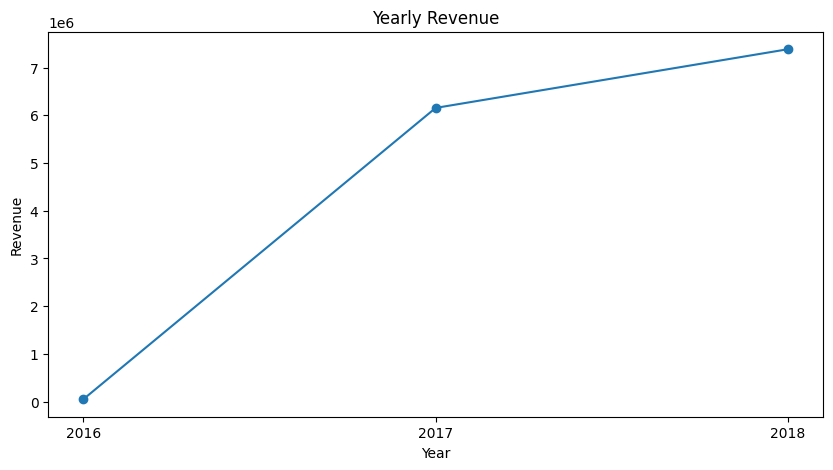

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_sales["Year"],
    yearly_sales["Revenue"],
    marker="o"
)

plt.title("Yearly Revenue")
plt.xlabel("Year")
plt.ylabel("Revenue")

plt.xticks(yearly_sales["Year"])

plt.show()

In [ ]:
monthly_sales = (
    sales_detail
    .groupby(
        ["Year", "Month Number", "Month Name"],
        as_index=False
    )["Revenue"]
    .sum()
    .sort_values(
        ["Year", "Month Number"]
    )
)

monthly_sales.head(12)

,Year,Month Number,Month Name,Revenue
0,2016,9,September,267.36
1,2016,10,October,49507.66
2,2016,12,December,10.90
3,2017,1,January,120312.87
4,2017,2,February,247303.02
5,2017,3,March,374344.30
6,2017,4,April,359927.23
7,2017,5,May,506071.14
8,2017,6,June,433038.60
9,2017,7,July,498031.48


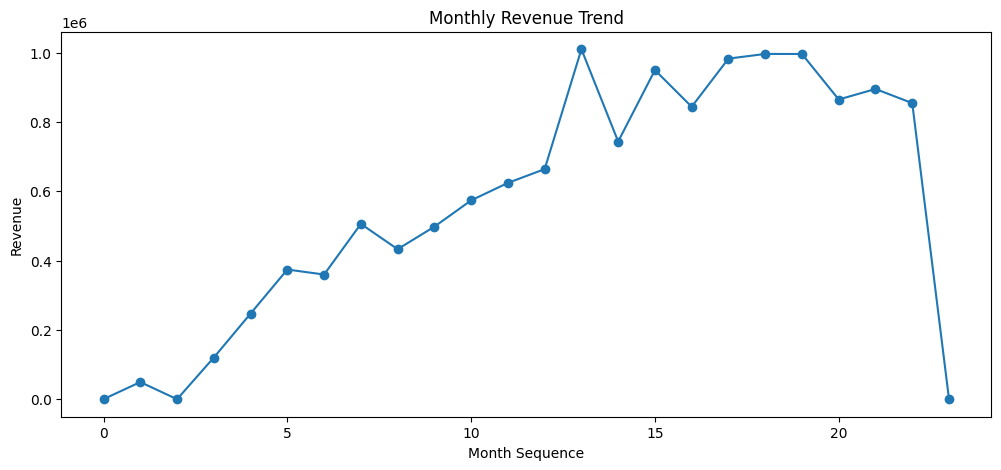

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(len(monthly_sales)),
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month Sequence")
plt.ylabel("Revenue")

plt.show()

Category Analysis

In [ ]:
category_sales_summary = (
    sales_detail
    .groupby("Category", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Order_Items=("Item Count", "sum")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

category_sales_summary.head(10)

,Category,Revenue,Order_Items
44,health_beauty,1258681.34,9670
73,watches_gifts,1205005.68,5991
8,bed_bath_table,1036988.68,11115
68,sports_leisure,988048.97,8641
16,computers_accessories,911954.32,7827
40,furniture_decor,729762.49,8334
21,cool_stuff,635290.85,3796
50,housewares,632248.66,6964
6,auto,592720.11,4235
43,garden_tools,485256.46,4347


In [ ]:
top_10_categories = category_sales_summary.head(10)

top_10_categories

,Category,Revenue,Order_Items
44,health_beauty,1258681.34,9670
73,watches_gifts,1205005.68,5991
8,bed_bath_table,1036988.68,11115
68,sports_leisure,988048.97,8641
16,computers_accessories,911954.32,7827
40,furniture_decor,729762.49,8334
21,cool_stuff,635290.85,3796
50,housewares,632248.66,6964
6,auto,592720.11,4235
43,garden_tools,485256.46,4347


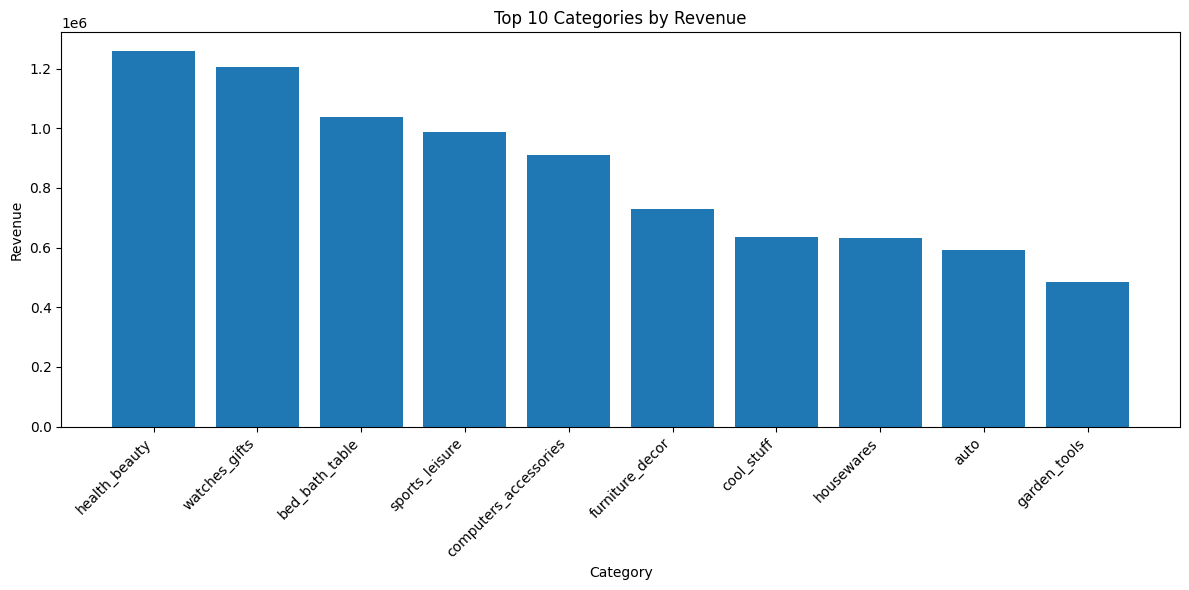

In [ ]:
#plot top 10 categories
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_categories["Category"],
    top_10_categories["Revenue"]
)

plt.title("Top 10 Categories by Revenue")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [ ]:
print("Sales detail rows:", len(sales_detail))
print("Sales detail columns:", len(sales_detail.columns))

sales_detail.head()

Sales detail rows: 112650
Sales detail columns: 18


,order_id,order_item_id,product_id,seller_id,price,freight_value,customer_id,order_status,order_purchase_timestamp,Year,Month Number,Month Name,Quarter,product_category_name,Category,Revenue,Item Count,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017,9,September,Q3,cool_stuff,cool_stuff,58.90,1,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017,4,April,Q2,pet_shop,pet_shop,239.90,1,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018,1,January,Q1,moveis_decoracao,furniture_decor,199.00,1,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018,8,August,Q3,perfumaria,perfumery,12.99,1,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017,2,February,Q1,ferramentas_jardim,garden_tools,199.90,1,64b576fb70d441e8f1b2d7d446e483c5


In [ ]:
total_revenue = sales_detail["Revenue"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 13591643.7


In [ ]:
total_orders = sales_detail["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 98666


In [ ]:
total_customers = sales_detail["customer_unique_id"].nunique()

print("Total Customers:", total_customers)

Total Customers: 95420


In [ ]:
average_order_value = total_revenue / total_orders

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 137.75


In [ ]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_customers,
        average_order_value
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,1.359164e+07
1,Total Orders,9.866600e+04
2,Total Customers,9.542000e+04
3,Average Order Value,1.377541e+02


Sales Trend

In [ ]:
yearly_sales = (
    sales_detail
    .groupby("Year", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("order_id", "nunique")
    )
    .sort_values("Year")
)

yearly_sales

,Year,Revenue,Orders
0,2016,49785.92,312
1,2017,6155806.98,44579
2,2018,7386050.80,53775


In [ ]:
#calculate yearly revenue growth
yearly_sales["Revenue Growth %"] = (
    yearly_sales["Revenue"]
    .pct_change()
    .mul(100)
)

yearly_sales

,Year,Revenue,Orders,Revenue Growth %
0,2016,49785.92,312,NaN
1,2017,6155806.98,44579,12264.554035
2,2018,7386050.80,53775,19.985094


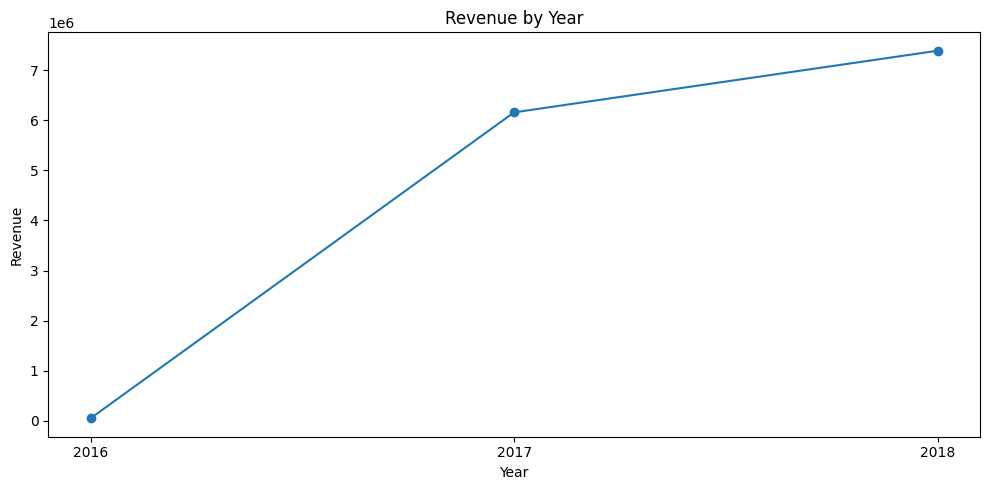

In [ ]:
#plot yearly revenue
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_sales["Year"],
    yearly_sales["Revenue"],
    marker="o"
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue")

plt.xticks(yearly_sales["Year"])

plt.tight_layout()
plt.show()

In [ ]:
#category order-item analysis
quarterly_sales = (
    sales_detail
    .groupby(
        ["Year", "Quarter"],
        as_index=False
    )
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("order_id", "nunique")
    )
)

quarterly_sales

,Year,Quarter,Revenue,Orders
0,2016,Q3,267.36,3
1,2016,Q4,49518.56,309
2,2017,Q1,741960.19,5163
3,2017,Q2,1299036.97,9268
4,2017,Q3,1696404.85,12505
5,2017,Q4,2418404.97,17643
6,2018,Q1,2777422.51,21102
7,2018,Q2,2858289.74,19947
8,2018,Q3,1750338.55,12726


In [ ]:
#Customer Analysis

In [ ]:
#customer level revenue table
customer_sales = (
    sales_detail
    .groupby("customer_unique_id", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("order_id", "nunique"),
        Order_Items=("Item Count", "sum")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

customer_sales.head(10)

,customer_unique_id,Revenue,Orders,Order_Items
3799,0a0a92112bd4c708ca5fde585afaa872,13440.0,1,8
81388,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2,2
44139,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1,4
82230,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1,1
26015,459bef486812aa25204be022145caa62,6729.0,1,1
95131,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0,1,1
23947,4007669dec559734d6f53e029e360987,5934.6,1,6
89056,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0,1,1
34820,5d0a2980b292d049061542014e8960bf,4599.9,1,2
27242,48e1ac109decbb87765a3eade6854098,4590.0,1,1


In [ ]:
#caluclate cusomer AOV
customer_sales["AOV"] = (
    customer_sales["Revenue"] /
    customer_sales["Orders"]
)

customer_sales.head(10)

,customer_unique_id,Revenue,Orders,Order_Items,AOV
3799,0a0a92112bd4c708ca5fde585afaa872,13440.0,1,8,13440.0
81388,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2,2,3694.0
44139,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1,4,7160.0
82230,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1,1,6735.0
26015,459bef486812aa25204be022145caa62,6729.0,1,1,6729.0
95131,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0,1,1,6499.0
23947,4007669dec559734d6f53e029e360987,5934.6,1,6,5934.6
89056,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0,1,1,4690.0
34820,5d0a2980b292d049061542014e8960bf,4599.9,1,2,4599.9
27242,48e1ac109decbb87765a3eade6854098,4590.0,1,1,4590.0


In [ ]:
#find top 10 customers by revenue
top_10_customers = customer_sales.head(10)

top_10_customers

,customer_unique_id,Revenue,Orders,Order_Items,AOV
3799,0a0a92112bd4c708ca5fde585afaa872,13440.0,1,8,13440.0
81388,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2,2,3694.0
44139,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1,4,7160.0
82230,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1,1,6735.0
26015,459bef486812aa25204be022145caa62,6729.0,1,1,6729.0
95131,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0,1,1,6499.0
23947,4007669dec559734d6f53e029e360987,5934.6,1,6,5934.6
89056,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0,1,1,4690.0
34820,5d0a2980b292d049061542014e8960bf,4599.9,1,2,4599.9
27242,48e1ac109decbb87765a3eade6854098,4590.0,1,1,4590.0


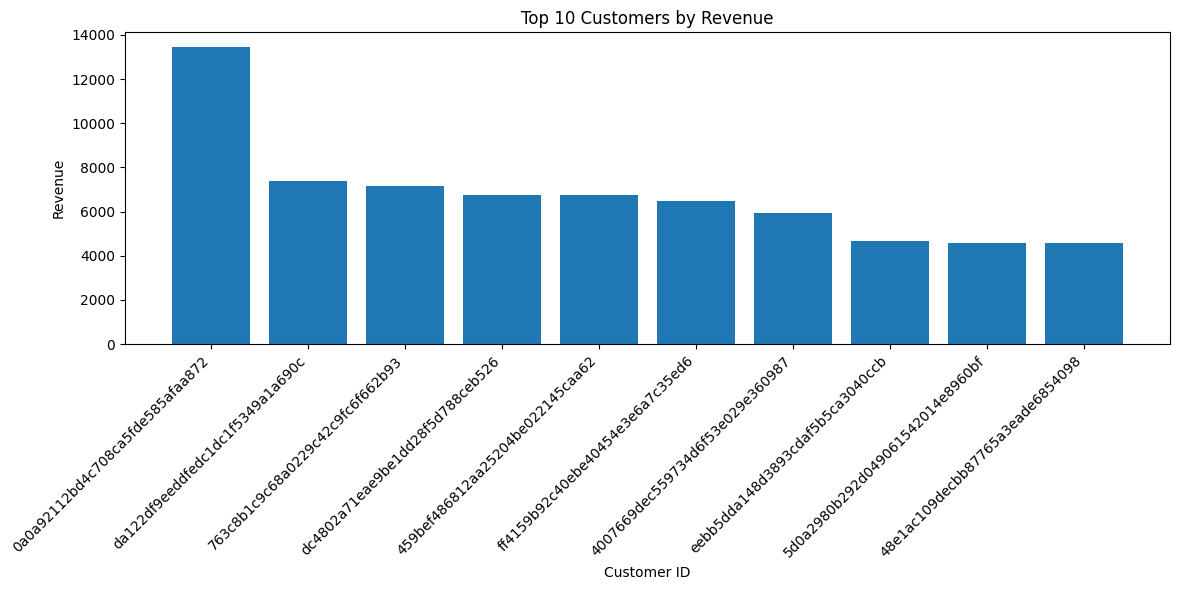

In [ ]:
#plot top 10 customers
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_customers["customer_unique_id"].astype(str),
    top_10_customers["Revenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
#identify repeat customers
repeat_customers = customer_sales[
    customer_sales["Orders"] > 1
].copy()

print(
    "Repeat customers:",
    len(repeat_customers)
)

print(
    "Total unique customers:",
    len(customer_sales)
)

Repeat customers: 2913
Total unique customers: 95420


In [ ]:
#calc repeat customer %
repeat_customer_percentage = (
    len(repeat_customers) /
    len(customer_sales)
) * 100

print(
    "Repeat customer percentage:",
    round(repeat_customer_percentage, 2),
    "%"
)

Repeat customer percentage: 3.05 %


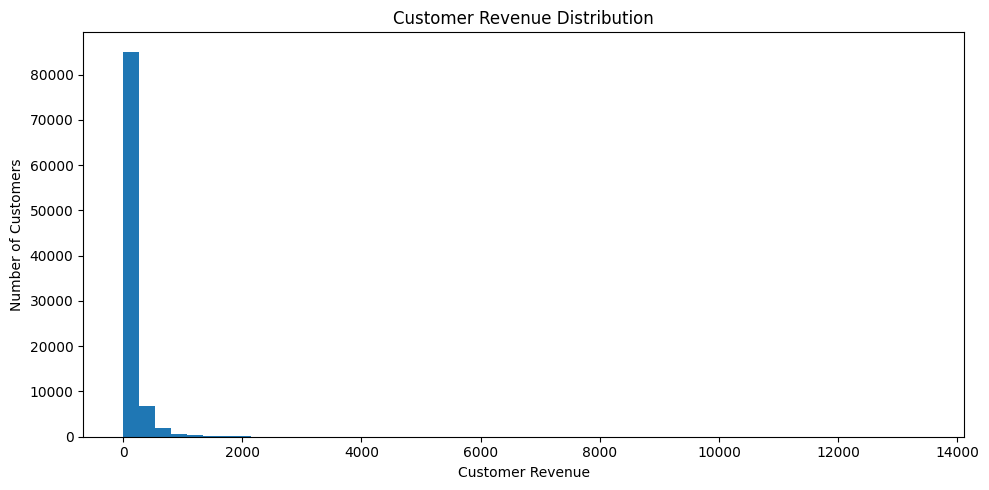

In [ ]:
#customer revenue distribution
plt.figure(figsize=(10, 5))

plt.hist(
    customer_sales["Revenue"],
    bins=50
)

plt.title("Customer Revenue Distribution")
plt.xlabel("Customer Revenue")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Regional Analysis


In [ ]:
customer_location = customers_analysis[
    [
        "customer_id",
        "customer_unique_id",
        "customer_state",
        "customer_city"
    ]
].copy()

customer_location.head()

,customer_id,customer_unique_id,customer_state,customer_city
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,SP,franca
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,SP,sao bernardo do campo
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,SP,sao paulo
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,SP,mogi das cruzes
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,SP,campinas


In [ ]:
#add customer state to sales detail
sales_detail = sales_detail.drop(
    columns=["customer_state", "customer_city"],
    errors="ignore"
)

sales_detail = sales_detail.merge(
    customer_location[
        [
            "customer_id",
            "customer_state",
            "customer_city"
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Sales detail shape:", sales_detail.shape)

Sales detail shape: (112650, 20)


In [ ]:
#revenue by state
state_sales = (
    sales_detail
    .groupby("customer_state", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_unique_id", "nunique")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

state_sales.head(10)

,customer_state,Revenue,Orders,Customers
25,SP,5202955.05,41375,39981
18,RJ,1824092.67,12762,12303
10,MG,1585308.03,11544,11178
22,RS,750304.02,5432,5249
17,PR,683083.76,4998,4840
23,SC,520553.34,3612,3513
4,BA,511349.99,3358,3257
6,DF,302603.94,2125,2062
8,GO,294591.95,2007,1942
7,ES,275037.31,2025,1956


In [ ]:
#top 10 states by revenue
top_10_states = state_sales.head(10)

top_10_states

,customer_state,Revenue,Orders,Customers
25,SP,5202955.05,41375,39981
18,RJ,1824092.67,12762,12303
10,MG,1585308.03,11544,11178
22,RS,750304.02,5432,5249
17,PR,683083.76,4998,4840
23,SC,520553.34,3612,3513
4,BA,511349.99,3358,3257
6,DF,302603.94,2125,2062
8,GO,294591.95,2007,1942
7,ES,275037.31,2025,1956


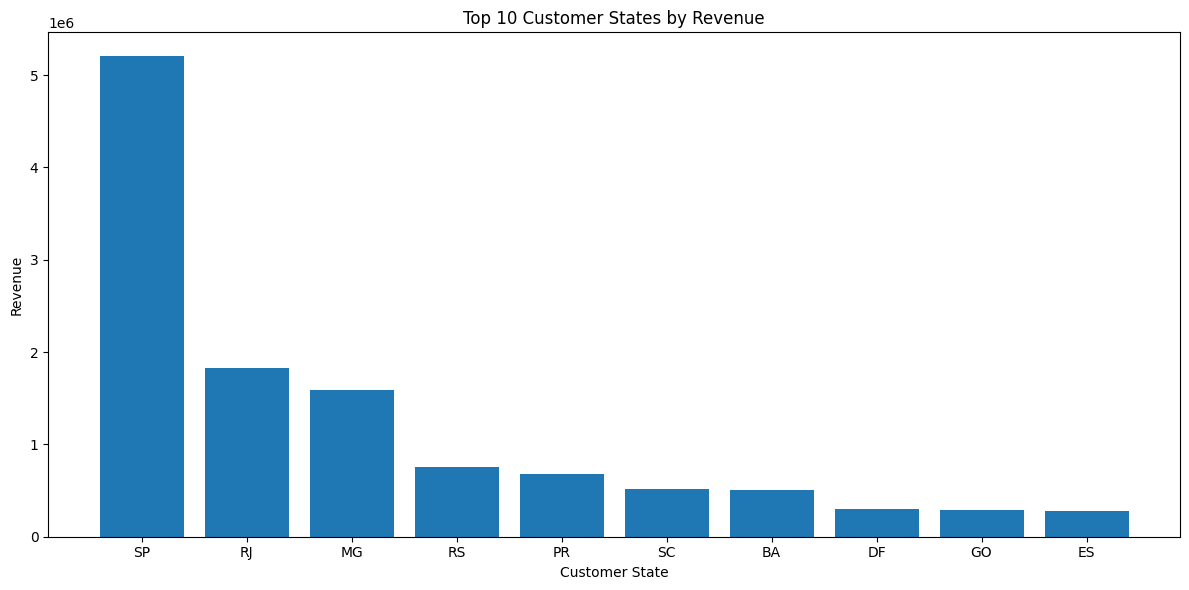

In [ ]:
#plot top 10 states
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_states["customer_state"],
    top_10_states["Revenue"]
)

plt.title("Top 10 Customer States by Revenue")
plt.xlabel("Customer State")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [ ]:
#payment method distribution
payment_method_summary = (
    payments_clean
    .groupby("payment_type", as_index=False)
    .agg(
        Payment_Count=("payment_type", "count"),
        Payment_Value=("payment_value", "sum")
    )
    .sort_values(
        "Payment_Value",
        ascending=False
    )
)

payment_method_summary

,payment_type,Payment_Count,Payment_Value
1,credit_card,76795,12542084.19
0,boleto,19784,2869361.27
4,voucher,5775,379436.87
2,debit_card,1529,217989.79
3,not_defined,3,0.00


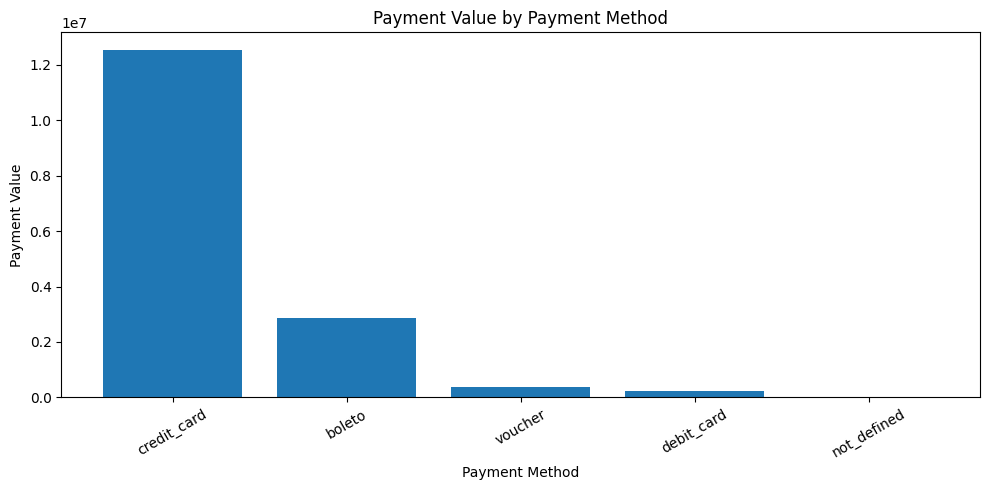

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    payment_method_summary["payment_type"],
    payment_method_summary["Payment_Value"]
)

plt.title("Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Payment Value")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
#review score distribution
review_summary = (
    reviews_clean
    .groupby("review_score", as_index=False)
    .agg(
        Review_Count=("review_score", "count")
    )
    .sort_values("review_score")
)

review_summary

,review_score,Review_Count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


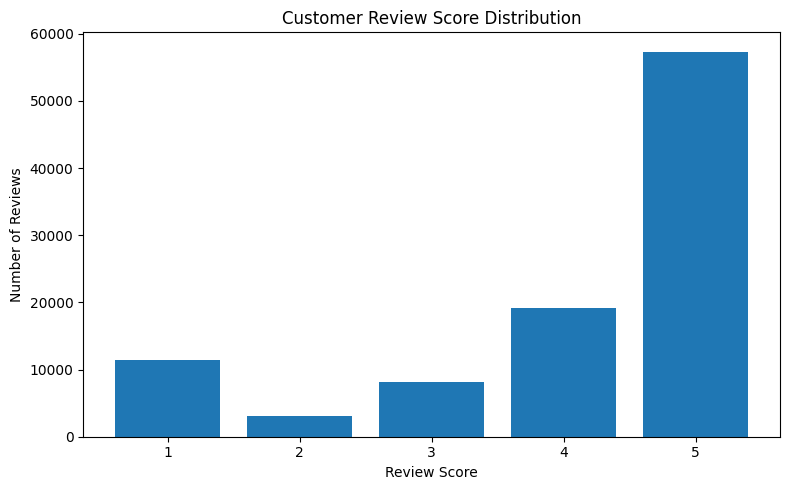

In [ ]:
#plot review scores
plt.figure(figsize=(8, 5))

plt.bar(
    review_summary["review_score"].astype(str),
    review_summary["Review_Count"]
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [ ]:
#save important analysis outputs
analysis_tables = {
    "kpi_summary": kpi_summary,
    "yearly_sales": yearly_sales,
    "monthly_sales": monthly_sales,
    "quarterly_sales": quarterly_sales,
    "category_sales_summary": category_sales_summary,
    "customer_sales": customer_sales,
    "state_sales": state_sales,
    "payment_method_summary": payment_method_summary,
    "review_summary": review_summary
}

for name, df in analysis_tables.items():
    file_path = os.path.join(
        CLEAN_PATH,
        f"{name}.csv"
    )

    df.to_csv(
        file_path,
        index=False
    )

print("✅ Analysis tables saved successfully.")

print("\nFiles created:")
for name in analysis_tables:
    print(f"- {name}.csv")

✅ Analysis tables saved successfully.

Files created:
- kpi_summary.csv
- yearly_sales.csv
- monthly_sales.csv
- quarterly_sales.csv
- category_sales_summary.csv
- customer_sales.csv
- state_sales.csv
- payment_method_summary.csv
- review_summary.csv


In [ ]:
#check the final sales structure
print("Rows:", len(sales_detail))
print("Columns:", len(sales_detail.columns))

sales_detail.head()

Rows: 112650
Columns: 20


,order_id,order_item_id,product_id,seller_id,price,freight_value,customer_id,order_status,order_purchase_timestamp,Year,Month Number,Month Name,Quarter,product_category_name,Category,Revenue,Item Count,customer_unique_id,customer_state,customer_city
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017,9,September,Q3,cool_stuff,cool_stuff,58.90,1,871766c5855e863f6eccc05f988b23cb,RJ,campos dos goytacazes
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017,4,April,Q2,pet_shop,pet_shop,239.90,1,eb28e67c4c0b83846050ddfb8a35d051,SP,santa fe do sul
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018,1,January,Q1,moveis_decoracao,furniture_decor,199.00,1,3818d81c6709e39d06b2738a8d3a2474,MG,para de minas
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018,8,August,Q3,perfumaria,perfumery,12.99,1,af861d436cfc08b2c2ddefd0ba074622,SP,atibaia
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017,2,February,Q1,ferramentas_jardim,garden_tools,199.90,1,64b576fb70d441e8f1b2d7d446e483c5,SP,varzea paulista


In [ ]:
#check for duplicate order item combinations
print(
    "Duplicate order-item combinations:",
    sales_detail[
        ["order_id", "order_item_id"]
    ].duplicated().sum()
)

Duplicate order-item combinations: 0


In [ ]:
#check missing essential analytical fields
essential_columns = [
    "order_id",
    "customer_id",
    "customer_unique_id",
    "product_id",
    "seller_id",
    "Revenue",
    "Year",
    "Month Number",
    "Quarter",
    "Category"
]

sales_detail[essential_columns].isnull().sum()

,0
order_id,0
customer_id,0
customer_unique_id,0
product_id,0
seller_id,0
Revenue,0
Year,0
Month Number,0
Quarter,0
Category,0


In [ ]:
#check revenue consistency
print("Revenue from sales_detail:", round(sales_detail["Revenue"].sum(), 2))
print("Revenue from order_items:", round(order_items_clean["price"].sum(), 2))

Revenue from sales_detail: 13591643.7
Revenue from order_items: 13591643.7


In [ ]:
#validate AOV
calculated_aov = (
    sales_detail["Revenue"].sum()
    / sales_detail["order_id"].nunique()
)

print("Calculated AOV:", round(calculated_aov, 2))
print("Stored AOV:", round(average_order_value, 2))

Calculated AOV: 137.75
Stored AOV: 137.75


Deeper Sales Analysis

In [ ]:
orders_by_year = (
    sales_detail
    .groupby("Year")
    .agg(
        Orders=("order_id", "nunique"),
        Revenue=("Revenue", "sum"),
        Customers=("customer_unique_id", "nunique")
    )
    .reset_index()
)

orders_by_year

,Year,Orders,Revenue,Customers
0,2016,312,49785.92,309
1,2017,44579,6155806.98,43225
2,2018,53775,7386050.80,52565


In [ ]:
#AOV by year
orders_by_year["AOV"] = (
    orders_by_year["Revenue"]
    / orders_by_year["Orders"]
)

orders_by_year

,Year,Orders,Revenue,Customers,AOV
0,2016,312,49785.92,309,159.570256
1,2017,44579,6155806.98,43225,138.087597
2,2018,53775,7386050.80,52565,137.351014


In [ ]:
#find the highest revenue year
best_year = orders_by_year.loc[
    orders_by_year["Revenue"].idxmax()
]

best_year

,2
Year,2.018000e+03
Orders,5.377500e+04
Revenue,7.386051e+06
Customers,5.256500e+04
AOV,1.373510e+02


In [ ]:
#find the highest order year
best_order_year = orders_by_year.loc[
    orders_by_year["Orders"].idxmax()
]

best_order_year
#

,2
Year,2.018000e+03
Orders,5.377500e+04
Revenue,7.386051e+06
Customers,5.256500e+04
AOV,1.373510e+02


In [ ]:
#calculate monthly order volume
monthly_orders = (
    sales_detail
    .groupby(
        ["Year", "Month Number", "Month Name"],
        as_index=False
    )
    .agg(
        Orders=("order_id", "nunique"),
        Customers=("customer_unique_id", "nunique")
    )
    .sort_values(
        ["Year", "Month Number"]
    )
)

monthly_orders.head(15)

,Year,Month Number,Month Name,Orders,Customers
0,2016,9,September,3,3
1,2016,10,October,308,305
2,2016,12,December,1,1
3,2017,1,January,789,755
4,2017,2,February,1733,1708
5,2017,3,March,2641,2601
6,2017,4,April,2391,2359
7,2017,5,May,3660,3588
8,2017,6,June,3217,3154
9,2017,7,July,3969,3894


Product Analysis

In [ ]:
#find products with most order item lines
top_products_by_volume = (
    sales_detail
    .groupby("product_id", as_index=False)
    .agg(
        Order_Items=("Item Count", "sum"),
        Revenue=("Revenue", "sum")
    )
    .sort_values(
        "Order_Items",
        ascending=False
    )
)

top_products_by_volume.head(10)

,product_id,Order_Items,Revenue
22112,aca2eb7d00ea1a7b8ebd4e68314663af,527,37608.90
19742,99a4788cb24856965c36a24e339b6058,488,43025.56
8613,422879e10f46682990de24d770e7f83d,484,26577.22
7364,389d119b48cf3043d311335e499d9c6b,392,21440.59
7079,368c6c730842d78016ad823897a372db,388,21056.80
10840,53759a2ecddad2bb87a079a1f1519f73,373,20387.20
27039,d1c427060a0f73f6b889a5c7c61f2ac4,343,47214.51
10867,53b36df67ebb7c41585e8d54d6772e08,323,37683.42
2794,154e7e31ebfa092203795c972e5804a6,281,6325.19
8051,3dd2a17168ec895c781a9191c1e95ad7,274,41082.60


In [ ]:
#compare top revenue products and top volume products
print("Top 5 products by revenue:")
top_revenue_products = top_products_by_volume.sort_values("Revenue", ascending=False).head(5)
print(
    top_revenue_products[
        ["product_id", "Revenue"]
    ]
)

print("\nTop 5 products by order-item volume:")
print(
    top_products_by_volume[
        ["product_id", "Order_Items"]
    ].head(5)
)

Top 5 products by revenue:
                             product_id   Revenue
24086  bb50f2e236e5eea0100680137654686c  63885.00
14068  6cdd53843498f92890544667809f1595  54730.20
27613  d6160fb7873f184099d9bc95e30376af  48899.34
27039  d1c427060a0f73f6b889a5c7c61f2ac4  47214.51
19742  99a4788cb24856965c36a24e339b6058  43025.56

Top 5 products by order-item volume:
                             product_id  Order_Items
22112  aca2eb7d00ea1a7b8ebd4e68314663af          527
19742  99a4788cb24856965c36a24e339b6058          488
8613   422879e10f46682990de24d770e7f83d          484
7364   389d119b48cf3043d311335e499d9c6b          392
7079   368c6c730842d78016ad823897a372db          388


In [ ]:
category_price = (
    sales_detail
    .groupby("Category", as_index=False)
    .agg(
        Average_Item_Price=("price", "mean"),
        Revenue=("Revenue", "sum"),
        Order_Items=("Item Count", "sum")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

category_price.head(10)

,Category,Average_Item_Price,Revenue,Order_Items
44,health_beauty,130.163531,1258681.34,9670
73,watches_gifts,201.135984,1205005.68,5991
8,bed_bath_table,93.296327,1036988.68,11115
68,sports_leisure,114.344285,988048.97,8641
16,computers_accessories,116.513903,911954.32,7827
40,furniture_decor,87.564494,729762.49,8334
21,cool_stuff,167.357969,635290.85,3796
50,housewares,90.788148,632248.66,6964
6,auto,139.957523,592720.11,4235
43,garden_tools,111.630196,485256.46,4347


CUstomer Analysis

In [ ]:
#customer order frequency distribution
order_frequency = (
    customer_sales["Orders"]
    .value_counts()
    .sort_index()
)

order_frequency

,count
Orders,
1,92507
2,2673
3,192
4,29
5,9
6,5
7,3
9,1
16,1


In [ ]:
#create customer purchase segments
customer_segments = customer_sales.copy()

customer_segments["Customer Type"] = np.where(
    customer_segments["Orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

customer_segments.head()

,customer_unique_id,Revenue,Orders,Order_Items,AOV,Customer Type
3799,0a0a92112bd4c708ca5fde585afaa872,13440.0,1,8,13440.0,One-Time Customer
81388,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2,2,3694.0,Repeat Customer
44139,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1,4,7160.0,One-Time Customer
82230,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1,1,6735.0,One-Time Customer
26015,459bef486812aa25204be022145caa62,6729.0,1,1,6729.0,One-Time Customer


In [ ]:
#count customer segments
customer_segment_summary = (
    customer_segments
    .groupby("Customer Type", as_index=False)
    .agg(
        Customers=("customer_unique_id", "count"),
        Revenue=("Revenue", "sum"),
        Orders=("Orders", "sum")
    )
)

customer_segment_summary

,Customer Type,Customers,Revenue,Orders
0,One-Time Customer,92507,12828351.84,92507
1,Repeat Customer,2913,763291.86,6159


In [ ]:
#calculate segment %s
customer_segment_summary["Segment %"] = (
    customer_segment_summary["Customers"]
    / customer_segment_summary["Customers"].sum()
) * 100

customer_segment_summary

,Customer Type,Customers,Revenue,Orders,Segment %
0,One-Time Customer,92507,12828351.84,92507,96.947181
1,Repeat Customer,2913,763291.86,6159,3.052819


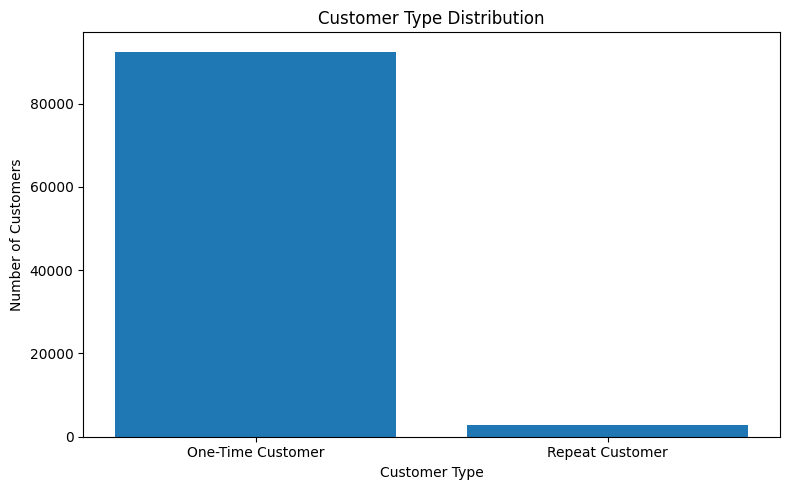

In [ ]:
#plot customer segments
plt.figure(figsize=(8, 5))

plt.bar(
    customer_segment_summary["Customer Type"],
    customer_segment_summary["Customers"]
)

plt.title("Customer Type Distribution")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

Regional Analysis

In [ ]:
#calculate state revenue contribution
state_sales["Revenue Contribution %"] = (
    state_sales["Revenue"]
    / total_revenue
    * 100
)

state_sales.head(10)

,customer_state,Revenue,Orders,Customers,Revenue Contribution %
25,SP,5202955.05,41375,39981,38.280543
18,RJ,1824092.67,12762,12303,13.420692
10,MG,1585308.03,11544,11178,11.663843
22,RS,750304.02,5432,5249,5.520333
17,PR,683083.76,4998,4840,5.025763
23,SC,520553.34,3612,3513,3.829951
4,BA,511349.99,3358,3257,3.762238
6,DF,302603.94,2125,2062,2.226397
8,GO,294591.95,2007,1942,2.167449
7,ES,275037.31,2025,1956,2.023577


In [ ]:
#find the strongest state
best_state = state_sales.iloc[0]

print("Top State:", best_state["customer_state"])
print("Revenue:", round(best_state["Revenue"], 2))
print("Customers:", best_state["Customers"])
print("Orders:", best_state["Orders"])

Top State: SP
Revenue: 5202955.05
Customers: 39981
Orders: 41375


In [ ]:
#calculate state level AOV
state_sales["AOV"] = (
    state_sales["Revenue"]
    / state_sales["Orders"]
)

state_sales.head(10)
#

,customer_state,Revenue,Orders,Customers,Revenue Contribution %,AOV
25,SP,5202955.05,41375,39981,38.280543,125.751179
18,RJ,1824092.67,12762,12303,13.420692,142.931568
10,MG,1585308.03,11544,11178,11.663843,137.327445
22,RS,750304.02,5432,5249,5.520333,138.126661
17,PR,683083.76,4998,4840,5.025763,136.671421
23,SC,520553.34,3612,3513,3.829951,144.117757
4,BA,511349.99,3358,3257,3.762238,152.278139
6,DF,302603.94,2125,2062,2.226397,142.401854
8,GO,294591.95,2007,1942,2.167449,146.782237
7,ES,275037.31,2025,1956,2.023577,135.820894


In [ ]:
#find states with highest AOV
highest_aov_states = (
    state_sales
    .sort_values("AOV", ascending=False)
    .head(10)
)

highest_aov_states

,customer_state,Revenue,Orders,Customers,Revenue Contribution %,AOV
14,PB,115268.08,532,516,0.848081,216.669323
3,AP,13474.30,68,67,0.099137,198.151471
0,AC,15982.95,81,77,0.117594,197.320370
1,AL,80314.81,411,399,0.590913,195.413163
20,RO,46140.64,247,235,0.339478,186.804211
13,PA,178947.81,970,944,1.316602,184.482278
26,TO,49621.74,279,272,0.365090,177.855699
16,PI,86914.08,493,481,0.639467,176.296308
12,MT,156453.53,903,873,1.151101,173.259723
19,RN,83034.98,482,471,0.610927,172.271743


Payment Analysis

In [ ]:
#calculate payment method %s
payment_method_summary["Payment %"] = (
    payment_method_summary["Payment_Value"]
    / payment_method_summary["Payment_Value"].sum()
    * 100
)

payment_method_summary

,payment_type,Payment_Count,Payment_Value,Payment %
1,credit_card,76795,12542084.19,78.344584
0,boleto,19784,2869361.27,17.923569
4,voucher,5775,379436.87,2.370166
2,debit_card,1529,217989.79,1.361681
3,not_defined,3,0.00,0.000000


In [ ]:
#find the dominant payment method
dominant_payment = payment_method_summary.iloc[0]

print(
    "Dominant payment method:",
    dominant_payment["payment_type"]
)

print(
    "Payment share:",
    round(dominant_payment["Payment %"], 2),
    "%"
)


Dominant payment method: credit_card
Payment share: 78.34 %


Review Analysis

In [ ]:
#calculate average review score
average_review_score = reviews_clean["review_score"].mean()

print(
    "Average Review Score:",
    round(average_review_score, 2)
)

Average Review Score: 4.09


In [ ]:
#calculate positive review %
positive_reviews = reviews_clean[
    reviews_clean["review_score"] >= 4
]

positive_review_percentage = (
    len(positive_reviews)
    / len(reviews_clean)
    * 100
)

print(
    "Positive Review Percentage:",
    round(positive_review_percentage, 2),
    "%"
)

Positive Review Percentage: 77.07 %


In [ ]:
#calculate negative review %
negative_reviews = reviews_clean[
    reviews_clean["review_score"] <= 2
]

negative_review_percentage = (
    len(negative_reviews)
    / len(reviews_clean)
    * 100
)

print(
    "Negative Review Percentage:",
    round(negative_review_percentage, 2),
    "%"
)

Negative Review Percentage: 14.69 %


Freight Analysis

In [ ]:
#calculate total freight
total_freight = sales_detail["freight_value"].sum()

print(
    "Total Freight Value:",
    round(total_freight, 2)
)

Total Freight Value: 2251909.54


In [ ]:
#calculate average freight per order item
average_freight = (
    sales_detail["freight_value"].mean()
)

print(
    "Average Freight per Order Item:",
    round(average_freight, 2)
)

Average Freight per Order Item: 19.99


In [ ]:
#compare revenue and freight by category
category_freight = (
    sales_detail
    .groupby("Category", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Freight=("freight_value", "sum")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

category_freight.head(10)

,Category,Revenue,Freight
44,health_beauty,1258681.34,182566.73
73,watches_gifts,1205005.68,100535.93
8,bed_bath_table,1036988.68,204693.04
68,sports_leisure,988048.97,168607.51
16,computers_accessories,911954.32,147318.08
40,furniture_decor,729762.49,172749.30
21,cool_stuff,635290.85,84039.10
50,housewares,632248.66,146149.11
6,auto,592720.11,92664.21
43,garden_tools,485256.46,98962.75


In [ ]:
#create a final KPI table
final_kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Average Order Value",
        "Total Order Items",
        "Total Freight Value",
        "Average Freight per Order Item",
        "Repeat Customer Percentage",
        "Average Review Score",
        "Positive Review Percentage"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_customers,
        average_order_value,
        len(sales_detail),
        total_freight,
        average_freight,
        repeat_customer_percentage,
        average_review_score,
        positive_review_percentage
    ]
})

final_kpis

,Metric,Value
0,Total Revenue,1.359164e+07
1,Total Orders,9.866600e+04
2,Total Customers,9.542000e+04
3,Average Order Value,1.377541e+02
4,Total Order Items,1.126500e+05
5,Total Freight Value,2.251910e+06
6,Average Freight per Order Item,1.999032e+01
7,Repeat Customer Percentage,3.052819e+00
8,Average Review Score,4.086421e+00
9,Positive Review Percentage,7.706805e+01


In [ ]:
#create a business insights reference
business_findings = {
    "Best Revenue Year": int(best_year["Year"]),
    "Best Revenue State": best_state["customer_state"],
    "Best Revenue Product": top_revenue_products.iloc[0]["product_id"],
    "Best Revenue Category": category_sales_summary.iloc[0]["Category"],
    "Dominant Payment Method": dominant_payment["payment_type"],
    "Repeat Customer Percentage": round(
        repeat_customer_percentage, 2
    ),
    "Average Review Score": round(
        average_review_score, 2
    ),
    "Positive Review Percentage": round(
        positive_review_percentage, 2
    )
}

business_findings

{'Best Revenue Year': 2018,
 'Best Revenue State': 'SP',
 'Best Revenue Product': 'bb50f2e236e5eea0100680137654686c',
 'Best Revenue Category': 'health_beauty',
 'Dominant Payment Method': 'credit_card',
 'Repeat Customer Percentage': 3.05,
 'Average Review Score': np.float64(4.09),
 'Positive Review Percentage': 77.07}

In [ ]:
#save additional analytical outputs
additional_analysis_tables = {
    "orders_by_year": orders_by_year,
    "monthly_orders": monthly_orders,
    "top_products_by_volume": top_products_by_volume,
    "category_price": category_price,
    "customer_segment_summary": customer_segment_summary,
    "state_sales": state_sales,
    "payment_method_summary": payment_method_summary,
    "review_summary": review_summary,
    "category_freight": category_freight,
    "final_kpis": final_kpis
}

for name, df in additional_analysis_tables.items():
    df.to_csv(
        os.path.join(
            CLEAN_PATH,
            f"{name}.csv"
        ),
        index=False
    )

print("✅ Additional analysis tables saved.")

✅ Additional analysis tables saved.


In [ ]:
#save the main analytical dataset
sales_detail.to_csv(
    os.path.join(
        CLEAN_PATH,
        "sales_detail.csv"
    ),
    index=False
)

print("✅ sales_detail.csv saved successfully.")

✅ sales_detail.csv saved successfully.


In [ ]:
#create the final python project checkpoint
print("=" * 60)
print("CODSOFT WEEK 3 — PYTHON ANALYSIS CHECKPOINT")
print("=" * 60)

print("\nMAIN DATASET")
print("Sales Detail Rows:", len(sales_detail))
print("Sales Detail Columns:", len(sales_detail.columns))

print("\nKEY KPIs")
print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", round(average_order_value, 2))

print("\nCUSTOMER")
print(
    "Repeat Customer %:",
    round(repeat_customer_percentage, 2)
)

print("\nREVIEW")
print(
    "Average Review Score:",
    round(average_review_score, 2)
)

print("\nFILES SAVED TO:")
print(CLEAN_PATH)

print("\n✅ PYTHON ANALYSIS CHECKPOINT COMPLETE")

CODSOFT WEEK 3 — PYTHON ANALYSIS CHECKPOINT

MAIN DATASET
Sales Detail Rows: 112650
Sales Detail Columns: 20

KEY KPIs
Total Revenue: 13591643.7
Total Orders: 98666
Total Customers: 95420
Average Order Value: 137.75

CUSTOMER
Repeat Customer %: 3.05

REVIEW
Average Review Score: 4.09

FILES SAVED TO:
/content/drive/MyDrive/CodSoft_Week3_Ecommerce_Analytics/02_Cleaned_Data

✅ PYTHON ANALYSIS CHECKPOINT COMPLETE


DONE WITH THE PROJECT

Creating few folders that were missing.

In [ ]:
import os

print("Files in 02_Cleaned_Data:")
for file in sorted(os.listdir(CLEAN_PATH)):
    if file.endswith(".csv"):
        print(file)

Files in 02_Cleaned_Data:
category_freight.csv
category_price.csv
category_sales_summary.csv
customer_sales.csv
customer_segment_summary.csv
final_kpis.csv
kpi_summary.csv
monthly_orders.csv
monthly_sales.csv
olist_customers_cleaned.csv
olist_geolocation_cleaned.csv
olist_order_items_cleaned.csv
olist_order_payments_cleaned.csv
olist_order_reviews_cleaned.csv
olist_orders_cleaned.csv
olist_products_cleaned.csv
olist_sellers_cleaned.csv
orders_by_year.csv
payment_method_summary.csv
product_category_name_translation_cleaned.csv
quarterly_sales.csv
review_summary.csv
sales_detail.csv
state_sales.csv
top_products_by_volume.csv
yearly_sales.csv


In [ ]:
import pandas as pd
import os

sales_detail_path = os.path.join(CLEAN_PATH, "sales_detail.csv")
sales_detail = pd.read_csv(sales_detail_path)

print("Available columns:")
print(sales_detail.columns.tolist())

Available columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'customer_id', 'order_status', 'order_purchase_timestamp', 'Year', 'Month Number', 'Month Name', 'Quarter', 'product_category_name', 'Category', 'Revenue', 'Item Count', 'customer_unique_id', 'customer_state', 'customer_city']


In [ ]:
# Identify the columns available in your sales detail file
columns = {col.lower().strip(): col for col in sales_detail.columns}

product_col = columns.get("product_id")
category_col = columns.get("category") or columns.get("product_category_name")
revenue_col = columns.get("revenue") or columns.get("price")
item_count_col = columns.get("item count")

if not product_col or not category_col or not revenue_col:
    raise ValueError(
        "A required column is missing. Check the column names printed above."
    )

# 1. Product sales by revenue
product_sales = (
    sales_detail.groupby(product_col, dropna=False)
    .agg(**{"Total Revenue": (revenue_col, "sum")})
    .reset_index()
    .rename(columns={product_col: "Product ID"})
    .sort_values("Total Revenue", ascending=False)
)

product_sales.to_csv(
    os.path.join(CLEAN_PATH, "product_sales.csv"), index=False
)

# 2. Order-item count by category
if item_count_col:
    category_volume = (
        sales_detail.groupby(category_col, dropna=False)
        .agg(**{"Order-Item Count": (item_count_col, "sum")})
        .reset_index()
    )
else:
    category_volume = (
        sales_detail.groupby(category_col, dropna=False)
        .size()
        .reset_index(name="Order-Item Count")
    )

category_volume = category_volume.rename(
    columns={category_col: "Category"}
).sort_values("Order-Item Count", ascending=False)

category_volume.to_csv(
    os.path.join(CLEAN_PATH, "category_volume.csv"), index=False
)

# 3. Average item price by category
category_price = (
    sales_detail.groupby(category_col, dropna=False)
    .agg(**{"Average Item Price": (revenue_col, "mean")})
    .reset_index()
    .rename(columns={category_col: "Category"})
    .sort_values("Average Item Price", ascending=False)
)

category_price.to_csv(
    os.path.join(CLEAN_PATH, "category_price.csv"), index=False
)

print("Created:")
print("product_sales.csv")
print("category_volume.csv")
print("category_price.csv")

Created:
product_sales.csv
category_volume.csv
category_price.csv


In [ ]:
for file in [
    "product_sales.csv",
    "category_volume.csv",
    "category_price.csv"
]:
    path = os.path.join(CLEAN_PATH, file)
    print(file, "—", "Found" if os.path.exists(path) else "Missing")

product_sales.csv — Found
category_volume.csv — Found
category_price.csv — Found
